# Fine-Tuned Transformers versus Classical Baselines for Requirements Classification Within and Across Projects

Adam Lane. EN.705.742 Advanced Applied Machine Learning. Research Project notebook.

This notebook is the code companion to the paper of the same title. It compares a TF-IDF and class weighted logistic regression baseline against a fine-tuned DistilBERT classifier on the PROMISE_exp requirements dataset for two tasks. Task A is the binary split of functional (F) versus non-functional (NFR) requirements. Task B is the fine grained classification of non-functional requirements into eleven quality types. The headline metric is macro F1. Both models are compared on 15 shared cross validation folds, on a held out test split, and on 15 folds in which whole projects are held out.

The notebook is organized in the same order as the paper.

1. Setup and configuration
2. Data loading and profiling
3. Evaluation protocols (held out test split, repeated stratified cross validation, and project grouped cross validation)
4. Baseline pipeline, TF-IDF with logistic regression, including the hyperparameter search
5. Proposed pipeline, DistilBERT fine-tuning in PyTorch, with a single fold sanity check
6. Statistical tests for the four hypotheses
7. Full experiment (search, paired folds, per class analysis, weighting ablation, cross project evaluation, learning curve, and summary)

Reproducing the results. The transformer experiments need the pretrained `distilbert-base-uncased` checkpoint and a CUDA GPU, and the 178 fine-tuning runs took 1.52 GPU hours. Each run is cached in `results/run_cache.json`, so a rerun with the cache present takes a few minutes, and deleting the cache forces a full rerun. If the checkpoint cannot be downloaded, the notebook falls back to a smoke test mode with a small, randomly initialized DistilBERT so that the code paths of Sections 1 to 6 still run, and Section 7 then stops with an explicit message.

Dataset. PROMISE_exp (Lima et al., SBES 2019) is public. The notebook expects `PROMISE_exp.csv` beside it. A copy is available at https://github.com/AleksandarMitrevski/se-requirements-classification under `1-exploratory-analysis/data/PROMISE_exp.csv`.

## 1. Setup and configuration

In [1]:
import os, json, random, time, warnings
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     StratifiedGroupKFold)
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DistilBertConfig,
                          DistilBertForSequenceClassification, PreTrainedTokenizerFast,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging

warnings.filterwarnings('ignore')
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Experiment configuration
TEST_SIZE = 0.20          # held out test fraction, stratified
N_SPLITS = 5              # folds per cross validation repeat
N_REPEATS = 3             # repeats of stratified 5-fold CV on the development split
MODEL_NAME = 'distilbert-base-uncased'
FIG_DIR = 'figures'
RESULTS_DIR = 'results'          # cached fine-tuning runs, so an interrupted run resumes
CP_SPLITS, CP_REPEATS = 5, 3    # cross project protocol, 15 project grouped folds
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)
COLORS = {'baseline': '#4C72B0', 'transformer': '#DD8452'}

print('torch', torch.__version__, '| device', DEVICE)

torch 2.7.1+cu128 | device cuda


## 2. Data loading and profiling

In [2]:
df = pd.read_csv('PROMISE_exp.csv')
df['RequirementText'] = df['RequirementText'].str.replace(r'\s+', ' ', regex=True).str.strip()
n_raw = len(df)
df = df.drop_duplicates('RequirementText').reset_index(drop=True)   # avoid the same text landing in train and test

CLASS_NAMES = {
    'F': 'Functional', 'A': 'Availability', 'FT': 'Fault Tolerance', 'L': 'Legal', 'LF': 'Look and Feel',
    'MN': 'Maintainability', 'O': 'Operability', 'PE': 'Performance', 'PO': 'Portability',
    'SC': 'Scalability', 'SE': 'Security', 'US': 'Usability'}

df['is_nfr'] = (df['_class_'] != 'F').astype(int)
df['n_words'] = df['RequirementText'].str.split().str.len()

print(f"Requirements: {len(df)} (raw {n_raw}, {n_raw - len(df)} duplicate removed after whitespace normalization) | projects: {df['ProjectID'].nunique()}")
print(f"Functional: {(df.is_nfr == 0).sum()} | Non-functional: {df.is_nfr.sum()}")
print(f"Words per requirement: median {df.n_words.median():.0f}, mean {df.n_words.mean():.1f}, max {df.n_words.max()}")
counts = df['_class_'].value_counts()
summary = pd.DataFrame({'label': counts.index, 'name': [CLASS_NAMES[c] for c in counts.index],
                        'count': counts.values, 'share_%': (100 * counts.values / len(df)).round(1)})
summary

Requirements: 968 (raw 969, 1 duplicate removed after whitespace normalization) | projects: 47
Functional: 444 | Non-functional: 524
Words per requirement: median 15, mean 17.9, max 86


,label,name,count,share_%
0,F,Functional,444,45.9
1,SE,Security,125,12.9
2,US,Usability,85,8.8
3,O,Operability,77,8.0
4,PE,Performance,66,6.8
5,LF,Look and Feel,49,5.1
6,A,Availability,31,3.2
7,MN,Maintainability,24,2.5
8,SC,Scalability,22,2.3
9,FT,Fault Tolerance,18,1.9


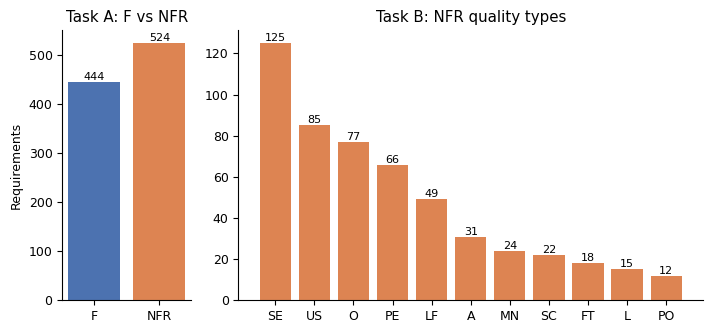

Task B imbalance ratio (largest / smallest class): 10.4


In [3]:
nfr_counts = df.loc[df.is_nfr == 1, '_class_'].value_counts()
plt.rcParams.update({'font.size': 9})
fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.4), gridspec_kw={'width_ratios': [1, 3.6]})
ax[0].bar(['F', 'NFR'], [(df.is_nfr == 0).sum(), df.is_nfr.sum()], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Task A: F vs NFR'); ax[0].set_ylabel('Requirements')
ax[1].bar(list(nfr_counts.index), nfr_counts.values, color='#DD8452')
ax[1].set_title('Task B: NFR quality types')
for a in ax:
    for p in a.patches:
        a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8)
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/class_distribution.png', dpi=200, bbox_inches='tight'); plt.show()
print(f"Task B imbalance ratio (largest / smallest class): {nfr_counts.max() / nfr_counts.min():.1f}")

The eleven quality types are strongly imbalanced. Security has roughly ten times as many requirements as Portability, so accuracy and weighted F1 would be dominated by the large classes. Macro F1 weights every class equally and is therefore the headline metric for Task B, with per class F1 reported to test H2.

## 3. Evaluation protocol

In [4]:
def make_task(task):
    # Return texts, integer labels, the label encoder, and project ids for task 'A' (F vs NFR) or 'B' (11 NFR types).
    if task == 'A':
        sub = df
        y_raw = np.where(sub.is_nfr == 1, 'NFR', 'F')
    else:
        sub = df[df.is_nfr == 1]
        y_raw = sub['_class_'].values
    le = LabelEncoder().fit(y_raw)
    return sub['RequirementText'].values, le.transform(y_raw), le, sub['ProjectID'].values

TASKS = {}
for task in ['A', 'B']:
    X, y, le, g = make_task(task)
    X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    folds = list(cv.split(X_dev, y_dev))     # identical folds are reused by both models for paired tests

    # Cross project protocol. Whole projects are held out, so no project contributes to both sides of a fold.
    cp_folds = []
    for r in range(CP_REPEATS):
        sgkf = StratifiedGroupKFold(n_splits=CP_SPLITS, shuffle=True, random_state=SEED + r)
        cp_folds += list(sgkf.split(X, y, g))
    assert all(not set(g[tr]) & set(g[va]) for tr, va in cp_folds)

    TASKS[task] = dict(X_dev=X_dev, y_dev=y_dev, X_test=X_test, y_test=y_test, le=le, folds=folds,
                       X_all=X, y_all=y, groups=g, cp_folds=cp_folds)
    cp_va = [len(va) for _, va in cp_folds]
    print(f"Task {task}: {len(le.classes_)} classes | dev {len(X_dev)} | test {len(X_test)} | CV folds {len(folds)} | "
          f"cross project folds {len(cp_folds)} over {len(np.unique(g))} projects (held out size {min(cp_va)} to {max(cp_va)})")

Task A: 2 classes | dev 774 | test 194 | CV folds 15 | cross project folds 15 over 47 projects (held out size 71 to 457)
Task B: 11 classes | dev 419 | test 105 | CV folds 15 | cross project folds 15 over 43 projects (held out size 51 to 194)


Each task is split once into a stratified development set (80 percent) and a held out test set (20 percent). The development set is evaluated with stratified 5-fold cross validation repeated three times, which yields 15 paired fold scores per model. Both models are trained and scored on exactly the same fold indices, so the per fold macro F1 differences form a paired sample for the hypothesis tests in Section 6. Hyperparameters are selected inside the development set only, and the test set is touched once per model at the end.

A second, cross project protocol asks a harder question. Random splits place requirements from the same project on both sides of a fold, so a model can profit from vocabulary that is specific to a project, such as product names or domain terms. The cross project protocol uses stratified group 5-fold cross validation on the full task data with the project as the group, repeated three times with different shuffles, so every validation fold contains only projects the model never saw in training. Both models are scored on the same 15 grouped folds, which again gives paired samples. This protocol tests H4.

## 4. Baseline pipeline. TF-IDF with logistic regression

In [5]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, sublinear_tf=True, strip_accents='unicode')),
    ('clf', LogisticRegression(max_iter=5000, class_weight='balanced', solver='lbfgs')),
])
BASELINE_GRID = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__min_df': [1, 2],
    'clf__C': [0.1, 1, 10, 100, 1000],
}

BASELINE = {}
for task in ['A', 'B']:
    T = TASKS[task]
    t0 = time.time()
    gs = GridSearchCV(baseline, BASELINE_GRID, scoring='f1_macro',
                      cv=StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED), n_jobs=-1)
    gs.fit(T['X_dev'], T['y_dev'])
    best = gs.best_params_

    # Paired fold scores with the selected configuration on the shared repeated CV folds
    fold_f1 = []
    for tr, va in T['folds']:
        m = baseline.set_params(**best).fit(T['X_dev'][tr], T['y_dev'][tr])
        fold_f1.append(f1_score(T['y_dev'][va], m.predict(T['X_dev'][va]), average='macro'))

    final = baseline.set_params(**best).fit(T['X_dev'], T['y_dev'])
    y_pred = final.predict(T['X_test'])
    BASELINE[task] = dict(best=best, fold_f1=np.array(fold_f1), y_pred=y_pred,
                          test_f1=f1_score(T['y_test'], y_pred, average='macro'))
    print(f"Task {task} | best {best} | grid {time.time() - t0:.1f}s")
    print(f"   CV macro F1 {np.mean(fold_f1):.3f} +/- {np.std(fold_f1, ddof=1):.3f} over {len(fold_f1)} folds | test macro F1 {BASELINE[task]['test_f1']:.3f}")

Task A | best {'clf__C': 100, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)} | grid 6.3s
   CV macro F1 0.900 +/- 0.018 over 15 folds | test macro F1 0.874
Task B | best {'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)} | grid 6.5s
   CV macro F1 0.606 +/- 0.059 over 15 folds | test macro F1 0.651


                 precision    recall  f1-score   support

   Availability      1.000     0.667     0.800         6
Fault Tolerance      0.500     0.250     0.333         4
          Legal      1.000     1.000     1.000         3
  Look and Feel      0.545     0.600     0.571        10
Maintainability      0.600     0.600     0.600         5
    Operability      0.900     0.562     0.692        16
    Performance      0.667     0.769     0.714        13
    Portability      0.333     0.500     0.400         2
    Scalability      0.500     0.500     0.500         4
       Security      0.750     0.840     0.792        25
      Usability      0.700     0.824     0.757        17

       accuracy                          0.705       105
      macro avg      0.681     0.647     0.651       105
   weighted avg      0.722     0.705     0.702       105



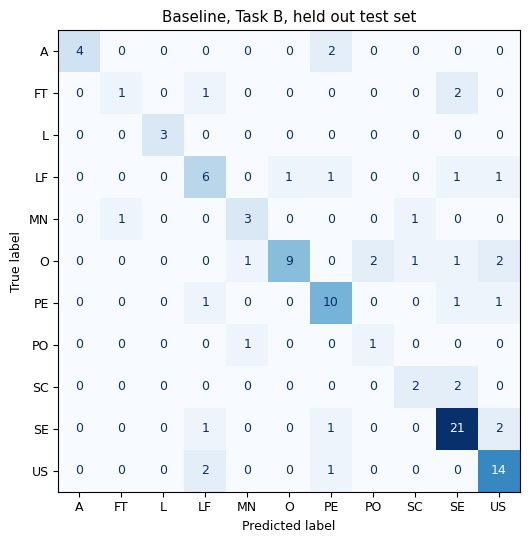

In [6]:
T = TASKS['B']
print(classification_report(T['y_test'], BASELINE['B']['y_pred'],
                            target_names=[CLASS_NAMES[c] for c in T['le'].classes_], digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(T['y_test'], BASELINE['B']['y_pred']),
                       display_labels=T['le'].classes_).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Baseline, Task B, held out test set')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/baseline_confusion_taskB.png', dpi=200, bbox_inches='tight'); plt.show()

Prototype observation. On Task A the baseline reaches a cross validated macro F1 of about 0.90, in line with the 0.91 that Canedo and Mendes (2020) report for TF-IDF with logistic regression on the same dataset. That level is high but not saturated, so H3 remains an open question for the full experiment rather than a foregone conclusion. On Task B the baseline drops to a cross validated macro F1 of about 0.61, and the per class report shows the weakness concentrated in small classes. Fault Tolerance, Portability, and Scalability fall at or below 0.50, while the large Security and Usability classes exceed 0.75. This is the gap H2 expects the transformer to narrow. The test macro F1 of 0.65 sits above the cross validated mean because several classes have only two to six test items, and removing a single duplicate requirement during development moved Portability from 0.00 to 0.40 on the test set. Per class figures therefore carry wide uncertainty, which is why the final paper reports them with bootstrap intervals and leans on the 15 paired cross validation folds for the hypothesis tests. These prototype figures are superseded by the full experiment in Section 7.

## 5. Proposed pipeline. DistilBERT fine-tuning in PyTorch

The proposed model fine-tunes DistilBERT with a classification head on the `[CLS]` representation. Given the final hidden state $h_{\text{CLS}} \in \mathbb{R}^{768}$, the head of `DistilBertForSequenceClassification` applies a dense layer with ReLU activation and dropout, then a linear layer and softmax, $\hat{p} = \operatorname{softmax}(W_2\,\operatorname{dropout}(\operatorname{ReLU}(W_1 h_{\text{CLS}} + b_1)) + b_2)$, and the model is trained end to end by minimizing the class weighted cross-entropy loss $\mathcal{L} = -\sum_{i} \alpha_{y_i} \log \hat{p}_{i, y_i} / \sum_{i} \alpha_{y_i}$ with AdamW and a linear warmup and decay schedule. The weights $\alpha_k = N/(K N_k)$ are the same inverse frequency weights the baseline uses, so both models treat the rare quality types alike and a per class difference cannot be attributed to the weighting alone. An unweighted variant is kept as an ablation in Section 7. On a GPU the forward pass runs in mixed precision (float16 autocast with gradient scaling), which roughly halves the training time without changing the method.

The loader below tries to download the pretrained checkpoint. If the checkpoint cannot be reached, it falls back to smoke test mode. In that mode a WordPiece tokenizer is trained on the development texts and a two layer DistilBERT with random weights is built, which exercises every line of the training and evaluation code without pretrained knowledge.

In [7]:
def load_model_factory(n_labels_by_task):
    try:
        tok = AutoTokenizer.from_pretrained(MODEL_NAME)
        AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)   # availability check
        mode = 'pretrained'
        def factory(n_labels):
            return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=n_labels)
    except Exception as e:
        print(f"Pretrained checkpoint unavailable ({type(e).__name__}). Running in SMOKE TEST mode.")
        from tokenizers import BertWordPieceTokenizer
        wp = BertWordPieceTokenizer(lowercase=True)
        wp.train_from_iterator(list(TASKS['A']['X_dev']), vocab_size=3000, min_frequency=1)
        tok = PreTrainedTokenizerFast(tokenizer_object=wp._tokenizer, unk_token='[UNK]', pad_token='[PAD]',
                                      cls_token='[CLS]', sep_token='[SEP]', mask_token='[MASK]')
        mode = 'smoke_test'
        def factory(n_labels):
            cfg = DistilBertConfig(vocab_size=tok.vocab_size, n_layers=2, n_heads=2, dim=64, hidden_dim=128,
                                   max_position_embeddings=128, num_labels=n_labels)
            return DistilBertForSequenceClassification(cfg)
    return tok, factory, mode

TOKENIZER, MODEL_FACTORY, RUN_MODE = load_model_factory({t: len(TASKS[t]['le'].classes_) for t in TASKS})
print('RUN_MODE =', RUN_MODE)

RUN_MODE = pretrained


In [8]:
class ReqDataset(Dataset):
    def __init__(self, texts, labels, tok, max_len):
        self.enc = tok(list(texts), truncation=True, padding='max_length', max_length=max_len, return_tensors='pt')
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return {'input_ids': self.enc['input_ids'][i], 'attention_mask': self.enc['attention_mask'][i], 'labels': self.labels[i]}

USE_AMP = DEVICE.type == 'cuda'      # mixed precision on GPU only

def class_weights(y, n_labels):
    # Inverse frequency weights N / (K N_k), matching class_weight='balanced' in scikit-learn.
    counts = np.bincount(y, minlength=n_labels).astype(float)
    k_present = (counts > 0).sum()
    return torch.tensor(np.where(counts > 0, len(y) / (k_present * np.maximum(counts, 1)), 0.0), dtype=torch.float)

@torch.no_grad()
def predict(model, loader):
    model.eval(); preds = []
    for b in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(input_ids=b['input_ids'].to(DEVICE), attention_mask=b['attention_mask'].to(DEVICE))
        preds.append(out.logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

def train_transformer(X_tr, y_tr, X_va, y_va, n_labels, lr=3e-5, epochs=4, max_len=64, batch_size=16,
                      warmup=0.1, weight_decay=0.01, class_weighted=True, seed=SEED, verbose=False):
    # Fine-tune one model and return (macro F1 on the validation texts, predictions, None).
    # The model is released after prediction to free GPU memory between the many runs of Section 7.
    set_seed(seed)
    model = MODEL_FACTORY(n_labels).to(DEVICE)
    tr_dl = DataLoader(ReqDataset(X_tr, y_tr, TOKENIZER, max_len), batch_size=batch_size, shuffle=True,
                       generator=torch.Generator().manual_seed(seed))
    va_dl = DataLoader(ReqDataset(X_va, y_va, TOKENIZER, max_len), batch_size=64)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = epochs * len(tr_dl)
    sched = get_linear_schedule_with_warmup(opt, int(warmup * steps), steps)
    weight = class_weights(y_tr, n_labels).to(DEVICE) if class_weighted else None
    loss_fn = nn.CrossEntropyLoss(weight=weight)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    for ep in range(epochs):
        model.train(); total = 0.0
        for b in tr_dl:
            opt.zero_grad()
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=b['input_ids'].to(DEVICE), attention_mask=b['attention_mask'].to(DEVICE)).logits
            loss = loss_fn(logits.float(), b['labels'].to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); total += loss.item()
        if verbose:
            print(f"   epoch {ep + 1}/{epochs} | train loss {total / len(tr_dl):.4f}")
    y_hat = predict(model, va_dl)
    del model, opt
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return f1_score(y_va, y_hat, average='macro'), y_hat, None

Hyperparameter search space for the full experiment. The learning rate and the number of epochs are tuned on the first cross validation repeat by mean validation macro F1. The epoch range extends to ten because the sanity check below shows the Task B training loss still falling at the sixth epoch. The maximum sequence length is fixed at 64 tokens. The pretrained tokenizer gives a median of 19 tokens and a 95th percentile of 46, and only 1.2 percent of requirements exceed 64, so a longer limit would change almost no inputs while roughly doubling the cost of every run. The token statistics are printed below to confirm this.

In [9]:
TRANSFORMER_GRID = {'lr': [2e-5, 3e-5, 5e-5], 'epochs': [4, 6, 10]}
MAX_LEN = 64

tok_lens = [len(TOKENIZER(t)['input_ids']) for t in TASKS['A']['X_dev']]
print(f"Token length ({RUN_MODE} tokenizer): median {np.median(tok_lens):.0f}, 95th pct {np.percentile(tok_lens, 95):.0f}, "
      f"share above {MAX_LEN} tokens {np.mean(np.array(tok_lens) > MAX_LEN):.1%}")
print(f"Search space: {len(TRANSFORMER_GRID['lr']) * len(TRANSFORMER_GRID['epochs'])} configurations per task")

Token length (pretrained tokenizer): median 19, 95th pct 46, share above 64 tokens 1.2%
Search space: 9 configurations per task


Sanity check. One fold of each task is trained to verify the pipeline end to end. In `pretrained` mode the check uses a fixed configuration from the search grid, six epochs at a learning rate of `5e-5`, which gives the small Task B training fold (about 335 requirements across eleven classes) enough optimizer steps to move beyond chance. The configuration is not tuned, so the scores are a check of real fine-tuning rather than results. In `smoke_test` mode the network has random weights and trains for two short epochs, so a macro F1 near chance is expected and confirms only that the code runs.

In [10]:
CHECK_CFG = {'lr': 5e-5, 'epochs': 6} if RUN_MODE == 'pretrained' else {'lr': 3e-5, 'epochs': 2}
SMOKE = {}
for task in ['A', 'B']:
    T = TASKS[task]; tr, va = T['folds'][0]
    t0 = time.time()
    f1, _, _ = train_transformer(T['X_dev'][tr], T['y_dev'][tr], T['X_dev'][va], T['y_dev'][va],
                                 n_labels=len(T['le'].classes_), verbose=True, **CHECK_CFG)
    SMOKE[task] = f1
    print(f"Task {task} [{RUN_MODE}] fold 1 macro F1 {f1:.3f} | lr {CHECK_CFG['lr']} | "
          f"{CHECK_CFG['epochs']} epochs | {time.time() - t0:.1f}s\n")

   epoch 1/6 | train loss 0.5844
   epoch 2/6 | train loss 0.2249
   epoch 3/6 | train loss 0.1082
   epoch 4/6 | train loss 0.0587
   epoch 5/6 | train loss 0.0217
   epoch 6/6 | train loss 0.0212
Task A [pretrained] fold 1 macro F1 0.941 | lr 5e-05 | 6 epochs | 27.2s

   epoch 1/6 | train loss 2.3869
   epoch 2/6 | train loss 2.1423
   epoch 3/6 | train loss 1.7000
   epoch 4/6 | train loss 1.2698
   epoch 5/6 | train loss 0.9542
   epoch 6/6 | train loss 0.7952
Task B [pretrained] fold 1 macro F1 0.663 | lr 5e-05 | 6 epochs | 12.8s



Sanity check observation. With pretrained weights and the class weighted loss, the first fold reaches a macro F1 of 0.941 on Task A and 0.663 on Task B under the fixed configuration. The Task B training loss is still falling at the sixth epoch, from 2.39 to 0.80, so the small eleven class training fold is sensitive to the training budget. This is the behavior the learning rate and epoch search in Section 7 is designed to resolve. These single fold scores verify the pipeline and are not reported as results.

## 6. Statistical testing scaffold

The hypotheses are tested with paired comparisons on the shared folds and on the held out test set.

H1 (Task B macro F1, transformer greater than baseline). One sided Nadeau and Bengio corrected resampled t-test on the 15 paired fold differences, which corrects the variance for the overlap between training sets in repeated cross validation. A Wilcoxon signed-rank test on the same differences serves as a nonparametric check, and a paired bootstrap gives a 95 percent confidence interval for the test set macro F1 difference.

H2 (gains concentrated in minority types). Per class F1 is computed from the out of fold predictions of each cross validation repeat, so every one of the 419 development requirements is scored once per repeat, and the three repeats are averaged. This is far more stable than the test split, which holds only two to six items of the smallest classes. The per class gain is related to class frequency by a Spearman rank correlation, and a negative correlation supports H2. Test set per class gains with bootstrap intervals are reported as a secondary view.

H3 (Task A saturated). The Task A macro F1 difference and its interval. Support for H3 is a small difference whose interval includes or nearly includes zero, together with both models above 0.90.

H4 (cross project robustness). The transformer's advantage over the baseline is larger when whole projects are held out than under random splits, because the baseline relies more on project specific vocabulary. The corrected t-test is applied to the 15 paired cross project fold differences, and a bootstrap over folds gives an interval for the cross project advantage minus the within project advantage. H4 is supported if that interval lies above zero.

In [11]:
def corrected_resampled_ttest(diffs, n_train, n_test, alternative='greater'):
    # Nadeau and Bengio (2003) corrected resampled t-test for repeated k-fold CV.
    d = np.asarray(diffs); J = len(d)
    var = np.var(d, ddof=1)
    t = d.mean() / np.sqrt((1 / J + n_test / n_train) * var) if var > 0 else np.inf * np.sign(d.mean())
    p = stats.t.sf(t, J - 1) if alternative == 'greater' else 2 * stats.t.sf(abs(t), J - 1)
    return t, p

def paired_bootstrap(y_true, pred_a, pred_b, n_boot=2000, seed=SEED, average='macro', labels=None):
    # Bootstrap distribution of F1(pred_b) minus F1(pred_a) over resampled test items.
    rng = np.random.default_rng(seed); n = len(y_true); out = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        fb = f1_score(y_true[i], pred_b[i], average=average, labels=labels, zero_division=0)
        fa = f1_score(y_true[i], pred_a[i], average=average, labels=labels, zero_division=0)
        out.append(fb - fa)
    out = np.array(out)
    return out.mean(), np.percentile(out, [2.5, 97.5], axis=0)

def compare(task, model_fold_f1, model_test_pred):
    T = TASKS[task]; B = BASELINE[task]
    diffs = np.asarray(model_fold_f1) - B['fold_f1'][:len(model_fold_f1)]
    n_va = len(T['folds'][0][1]); n_tr = len(T['folds'][0][0])
    t, p_t = corrected_resampled_ttest(diffs, n_tr, n_va)
    w = stats.wilcoxon(diffs, alternative='greater') if np.any(diffs != 0) and len(diffs) > 5 else None
    d_mean, ci = paired_bootstrap(T['y_test'], B['y_pred'], model_test_pred)
    return {'task': task, 'mean_fold_diff': diffs.mean(), 't': t, 'p_corrected_t': p_t,
            'p_wilcoxon': (w.pvalue if w is not None else np.nan), 'test_diff': d_mean, 'ci_low': ci[0], 'ci_high': ci[1]}

def per_class_gain(task, model_test_pred):
    T = TASKS[task]; B = BASELINE[task]
    f_b = precision_recall_fscore_support(T['y_test'], B['y_pred'], zero_division=0)[2]
    f_m = precision_recall_fscore_support(T['y_test'], model_test_pred, zero_division=0)[2]
    freq = np.bincount(T['y_dev'], minlength=len(T['le'].classes_))
    tab = pd.DataFrame({'class': T['le'].classes_, 'train_count': freq, 'f1_baseline': f_b, 'f1_transformer': f_m,
                        'gain': f_m - f_b}).sort_values('train_count')
    rho, p = stats.spearmanr(tab.train_count, tab.gain)
    return tab, rho, p

print('Scaffold ready. Functions: corrected_resampled_ttest, paired_bootstrap, compare, per_class_gain')

Scaffold ready. Functions: corrected_resampled_ttest, paired_bootstrap, compare, per_class_gain


Pipeline check of the statistics code. To confirm the functions run on real inputs, they are applied below to the baseline against a deliberately weaker unigram, unweighted logistic regression on the same folds. This exercises the code path that the transformer comparison will use. It is a mechanics check, not a test of any hypothesis.

In [12]:
weak = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 1))), ('clf', LogisticRegression(max_iter=5000, C=1.0))])
T = TASKS['B']
weak_folds = [f1_score(T['y_dev'][va], weak.fit(T['X_dev'][tr], T['y_dev'][tr]).predict(T['X_dev'][va]), average='macro')
              for tr, va in T['folds']]
weak_pred = weak.fit(T['X_dev'], T['y_dev']).predict(T['X_test'])
check = compare('B', weak_folds, weak_pred)       # 'model' here is the weak reference, so a negative difference is expected
pd.Series({k: v for k, v in check.items() if k != 'task'}).round(4)

mean_fold_diff   -0.2540
t                -6.1906
p_corrected_t     1.0000
p_wilcoxon        1.0000
test_diff        -0.3055
ci_low           -0.4340
ci_high          -0.1753
dtype: float64

## 7. Full experiment

The cells below run the complete transformer experiment with `RUN_MODE == 'pretrained'` on a GPU. Every fine-tuning run is cached in `results/run_cache.json` as soon as it finishes, keyed by task, protocol, fold, and configuration. If the kernel stops partway, Restart and Run All resumes from the cache and repeats no finished run. Deleting the cache file forces a clean rerun. The section has six parts.

1. Hyperparameter search over `TRANSFORMER_GRID` on the first CV repeat, then the selected configuration on all 15 shared folds and once on the held out test set (H1 and H3).
2. Per class analysis from out of fold predictions and from the test set (H2).
3. Loss weighting ablation on Task B, with both models trained with and without class weights on the same folds.
4. Cross project evaluation on 15 project grouped folds (H4).
5. Learning curve at 25, 50, and 100 percent of each training fold.
6. Summary tables, figures, and `results/summary.json`, which collects every number reported in the paper.

The completed experiment comprises 178 fine-tuning runs, about 31 seconds each on average, for 1.52 GPU hours in total.

In [13]:
RUN_FULL = True
LC_FRACTIONS = [0.25, 0.5]

assert not RUN_FULL or RUN_MODE == 'pretrained', 'The full experiment requires the pretrained DistilBERT checkpoint.'

CACHE_PATH = f'{RESULTS_DIR}/run_cache.json'
RUN_CACHE = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
print(f"{len(RUN_CACHE)} cached runs loaded from {CACHE_PATH}")

def cfg_key(cfg, class_weighted=True):
    return f"lr={cfg['lr']:g}|ep={cfg['epochs']}|len={cfg['max_len']}|w={int(class_weighted)}"

def cached_transformer(key, X_tr, y_tr, X_va, y_va, n_labels, class_weighted=True, **cfg):
    # Run one fine-tuning job, or return its cached F1 and predictions if it already ran.
    key = f"{RUN_MODE}|{key}"
    if key not in RUN_CACHE:
        t0 = time.time()
        f1, pred, _ = train_transformer(X_tr, y_tr, X_va, y_va, n_labels, class_weighted=class_weighted, **cfg)
        RUN_CACHE[key] = {'f1': float(f1), 'pred': [int(p) for p in pred], 'sec': round(time.time() - t0, 1)}
        with open(CACHE_PATH + '.tmp', 'w') as fh:
            json.dump(RUN_CACHE, fh)
        os.replace(CACHE_PATH + '.tmp', CACHE_PATH)
        print(f"   ran {key} | F1 {f1:.3f} | {RUN_CACHE[key]['sec']}s | {len(RUN_CACHE)} runs cached")
    r = RUN_CACHE[key]
    return r['f1'], np.array(r['pred'])

def fit_baseline(task, X_tr, y_tr, class_weighted=True):
    m = clone(baseline).set_params(**BASELINE[task]['best'])
    if not class_weighted:
        m.set_params(clf__class_weight=None)
    return m.fit(X_tr, y_tr)

def macro_f1_present(y_true, y_pred):
    # Macro F1 over the classes present in y_true. Used for project grouped folds, where a rare class can be absent.
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average='macro', zero_division=0)

178 cached runs loaded from results/run_cache.json


### 7.1 Hyperparameter search, paired cross validation, and held out test (H1, H3)

In [14]:
RESULTS = {}
for task in ['A', 'B']:
    if not RUN_FULL:
        break
    T = TASKS[task]; n_lab = len(T['le'].classes_); t0 = time.time()

    def cv_run(i, cfg, class_weighted=True, task=task, T=T, n_lab=n_lab):   # defaults bind this task
        tr, va = T['folds'][i]
        return cached_transformer(f"{task}|cv|f{i}|{cfg_key(cfg, class_weighted)}", T['X_dev'][tr], T['y_dev'][tr],
                                  T['X_dev'][va], T['y_dev'][va], n_lab, class_weighted=class_weighted, **cfg)

    search = []
    for lr, ep in product(TRANSFORMER_GRID['lr'], TRANSFORMER_GRID['epochs']):
        cfg = {'lr': lr, 'epochs': ep, 'max_len': MAX_LEN}
        s = [cv_run(i, cfg)[0] for i in range(N_SPLITS)]          # first repeat only
        search.append({**cfg, 'cv_macro_f1': np.mean(s), 'cv_std': np.std(s, ddof=1)})
    search = pd.DataFrame(search).sort_values('cv_macro_f1', ascending=False).reset_index(drop=True)
    best = {'lr': float(search.loc[0, 'lr']), 'epochs': int(search.loc[0, 'epochs']), 'max_len': MAX_LEN}

    # The selected configuration on all 15 folds. The first five reuse the cached search runs.
    runs = [cv_run(i, best) for i in range(len(T['folds']))]
    fold_f1 = np.array([r[0] for r in runs]); fold_pred = [r[1] for r in runs]
    test_f1, test_pred = cached_transformer(f"{task}|test|{cfg_key(best)}", T['X_dev'], T['y_dev'],
                                            T['X_test'], T['y_test'], n_lab, **best)
    RESULTS[task] = dict(search=search, best=best, fold_f1=fold_f1, fold_pred=fold_pred, test_pred=test_pred,
                         test_f1=test_f1, stats=compare(task, fold_f1, test_pred), cv_run=cv_run)
    print(f"Task {task} | best {best} | CV macro F1 {fold_f1.mean():.3f} +/- {fold_f1.std(ddof=1):.3f} | "
          f"test {test_f1:.3f} | {(time.time() - t0) / 60:.1f} min")
    display(search.assign(lr=search.lr.map('{:g}'.format)).round(4))

if RUN_FULL:
    stats_tab = pd.DataFrame([RESULTS[t]['stats'] for t in ['A', 'B']]).set_index('task')
    display(stats_tab.round(4))
    # Selection check. The transformer configuration was chosen on folds 1 to 5, so rescore on folds 6 to 15 only.
    for task in ['A', 'B']:
        T = TASKS[task]; d = (RESULTS[task]['fold_f1'] - BASELINE[task]['fold_f1'])[N_SPLITS:]
        t, p = corrected_resampled_ttest(d, len(T['folds'][0][0]), len(T['folds'][0][1]))
        print(f"Task {task} folds not used for selection: mean gain {d.mean():.4f}, corrected t {t:.2f}, p {p:.4f} | "
              f"wins {(RESULTS[task]['fold_f1'] > BASELINE[task]['fold_f1']).sum()} of {len(d) + N_SPLITS}")

Task A | best {'lr': 5e-05, 'epochs': 6, 'max_len': 64} | CV macro F1 0.922 +/- 0.022 | test 0.881 | 0.1 min


,lr,epochs,max_len,cv_macro_f1,cv_std
0,5e-05,6,64,0.9231,0.0219
1,2e-05,10,64,0.9205,0.0255
2,5e-05,4,64,0.9192,0.0238
3,3e-05,10,64,0.9129,0.0237
4,5e-05,10,64,0.9116,0.0153
5,2e-05,6,64,0.9113,0.0305
6,3e-05,6,64,0.9075,0.0174
7,3e-05,4,64,0.8996,0.0162
8,2e-05,4,64,0.8918,0.0222


Task B | best {'lr': 3e-05, 'epochs': 10, 'max_len': 64} | CV macro F1 0.642 +/- 0.049 | test 0.644 | 0.1 min


,lr,epochs,max_len,cv_macro_f1,cv_std
0,3e-05,10,64,0.6423,0.0396
1,5e-05,10,64,0.6413,0.0435
2,5e-05,6,64,0.6240,0.0401
3,2e-05,10,64,0.5895,0.0654
4,3e-05,6,64,0.5591,0.0644
5,5e-05,4,64,0.5455,0.0653
6,2e-05,6,64,0.5044,0.0590
7,3e-05,4,64,0.4624,0.0456
8,2e-05,4,64,0.3607,0.0533


,mean_fold_diff,t,p_corrected_t,p_wilcoxon,test_diff,ci_low,ci_high
task,,,,,,,
A,0.0220,2.1183,0.0263,0.0008,0.0058,-0.0382,0.0516
B,0.0359,1.2937,0.1084,0.0108,-0.0008,-0.1048,0.0989


Task A folds not used for selection: mean gain 0.0208, corrected t 2.29, p 0.0239 | wins 12 of 15
Task B folds not used for selection: mean gain 0.0287, corrected t 1.17, p 0.1355 | wins 11 of 15


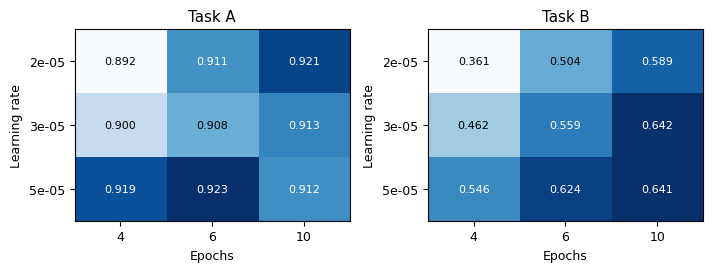

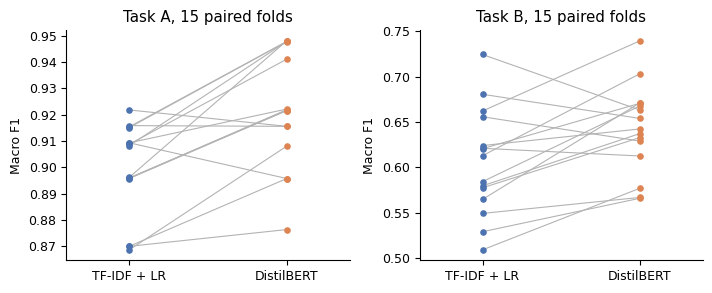

In [15]:
if RUN_FULL:
    # Search sensitivity, mean first repeat macro F1 over learning rate and epochs
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for ax, task in zip(axes, ['A', 'B']):
        piv = RESULTS[task]['search'].pivot(index='lr', columns='epochs', values='cv_macro_f1').sort_index()
        im = ax.imshow(piv.values, cmap='Blues', aspect='auto')
        ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), [f'{v:g}' for v in piv.index])
        ax.set_xlabel('Epochs'); ax.set_ylabel('Learning rate'); ax.set_title(f'Task {task}')
        lo, hi = np.nanmin(piv.values), np.nanmax(piv.values)
        for (r, c), v in np.ndenumerate(piv.values):
            ax.text(c, r, f'{v:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if v > lo + 0.6 * (hi - lo) else 'black')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/hp_search.png', dpi=200, bbox_inches='tight'); plt.show()

    # Paired fold scores, one line per fold
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
    for ax, task in zip(axes, ['A', 'B']):
        b, m = BASELINE[task]['fold_f1'], RESULTS[task]['fold_f1']
        for bi, mi in zip(b, m):
            ax.plot([0, 1], [bi, mi], color='0.7', lw=0.8, zorder=1)
        ax.scatter(np.zeros_like(b), b, color=COLORS['baseline'], zorder=2, s=14)
        ax.scatter(np.ones_like(m), m, color=COLORS['transformer'], zorder=2, s=14)
        ax.set_xticks([0, 1], ['TF-IDF + LR', 'DistilBERT']); ax.set_xlim(-0.4, 1.4)
        ax.set_title(f'Task {task}, 15 paired folds'); ax.set_ylabel('Macro F1')
        ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fold_scores.png', dpi=200, bbox_inches='tight'); plt.show()

### 7.2 Per class analysis (H2)

H2 Spearman (train count vs gain): out of fold rho 0.018 (p 0.958) | test rho -0.009 (p 0.979)


,class,name,train_count,test_f1_baseline,test_f1_transformer,test_gain,test_ci_low,test_ci_high,oof_f1_baseline,oof_f1_transformer,oof_gain
7,PO,Portability,10,0.400,0.571,0.171,-0.267,0.800,0.368,0.500,0.132
2,L,Legal,12,1.000,1.000,0.000,0.000,0.000,0.517,0.704,0.187
1,FT,Fault Tolerance,14,0.333,0.000,-0.333,-0.800,0.000,0.444,0.442,-0.002
8,SC,Scalability,18,0.500,0.444,-0.056,-0.267,0.143,0.765,0.770,0.005
4,MN,Maintainability,19,0.600,0.500,-0.100,-0.571,0.267,0.509,0.425,-0.084
0,A,Availability,25,0.800,0.909,0.109,0.000,0.457,0.725,0.692,-0.033
3,LF,Look and Feel,39,0.571,0.700,0.129,-0.134,0.413,0.667,0.679,0.011
6,PE,Performance,53,0.714,0.667,-0.048,-0.297,0.172,0.764,0.790,0.027
5,O,Operability,61,0.692,0.690,-0.003,-0.202,0.194,0.576,0.597,0.021
10,US,Usability,68,0.757,0.684,-0.073,-0.256,0.103,0.642,0.699,0.057


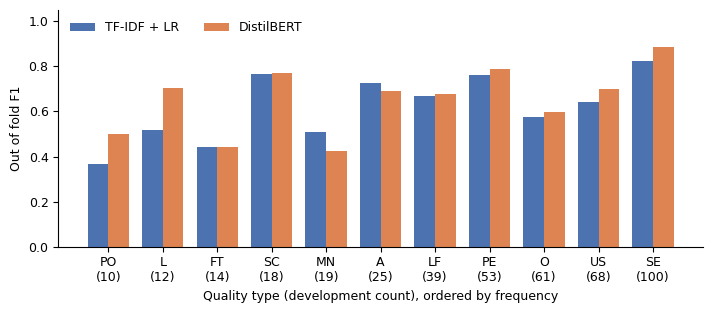

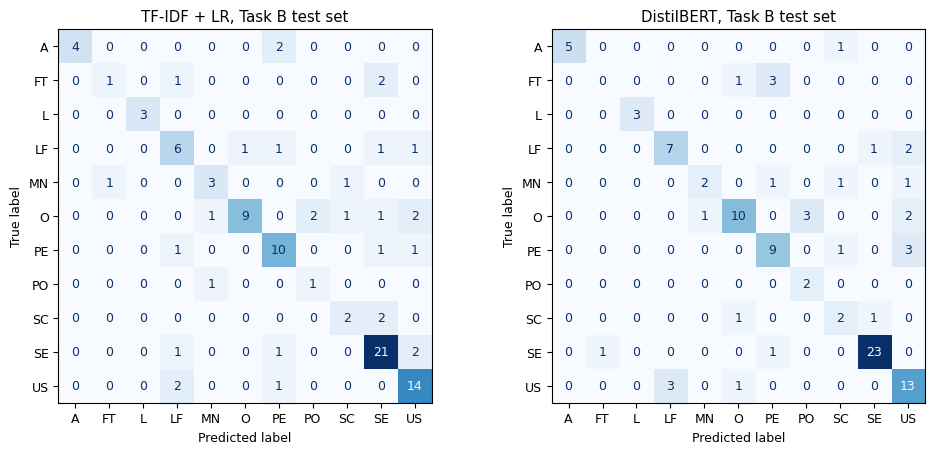

                 precision    recall  f1-score   support

   Availability      1.000     0.833     0.909         6
Fault Tolerance      0.000     0.000     0.000         4
          Legal      1.000     1.000     1.000         3
  Look and Feel      0.700     0.700     0.700        10
Maintainability      0.667     0.400     0.500         5
    Operability      0.769     0.625     0.690        16
    Performance      0.643     0.692     0.667        13
    Portability      0.400     1.000     0.571         2
    Scalability      0.400     0.500     0.444         4
       Security      0.920     0.920     0.920        25
      Usability      0.619     0.765     0.684        17

       accuracy                          0.724       105
      macro avg      0.647     0.676     0.644       105
   weighted avg      0.723     0.724     0.716       105



In [16]:
def per_class_bootstrap(y_true, pred_a, pred_b, n_labels, n_boot=2000, seed=SEED):
    # 95 percent bootstrap interval of the per class F1 gain, pred_b minus pred_a, on the test set.
    rng = np.random.default_rng(seed); labels = np.arange(n_labels); n = len(y_true); out = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        out.append(f1_score(y_true[i], pred_b[i], labels=labels, average=None, zero_division=0)
                   - f1_score(y_true[i], pred_a[i], labels=labels, average=None, zero_division=0))
    return np.percentile(np.array(out), [2.5, 97.5], axis=0)

def oof_per_class(task, fold_preds):
    # Per class F1 from out of fold predictions, one score per CV repeat, averaged over the repeats.
    T = TASKS[task]; K = len(T['le'].classes_); scores = []
    for r in range(N_REPEATS):
        oof = np.full(len(T['y_dev']), -1)
        for i in range(r * N_SPLITS, (r + 1) * N_SPLITS):
            oof[T['folds'][i][1]] = fold_preds[i]
        assert (oof >= 0).all()
        scores.append(f1_score(T['y_dev'], oof, labels=np.arange(K), average=None, zero_division=0))
    return np.mean(scores, axis=0)

if RUN_FULL:
    T = TASKS['B']; K = len(T['le'].classes_)
    base_fold_pred = [fit_baseline('B', T['X_dev'][tr], T['y_dev'][tr]).predict(T['X_dev'][va]) for tr, va in T['folds']]
    gain_tab, rho_test, p_rho_test = per_class_gain('B', RESULTS['B']['test_pred'])
    ci = per_class_bootstrap(T['y_test'], BASELINE['B']['y_pred'], RESULTS['B']['test_pred'], K)
    gain_tab['test_ci_low'] = ci[0][gain_tab.index]; gain_tab['test_ci_high'] = ci[1][gain_tab.index]
    gain_tab = gain_tab.rename(columns={'f1_baseline': 'test_f1_baseline', 'f1_transformer': 'test_f1_transformer', 'gain': 'test_gain'})
    gain_tab['oof_f1_baseline'] = oof_per_class('B', base_fold_pred)[gain_tab.index]
    gain_tab['oof_f1_transformer'] = oof_per_class('B', RESULTS['B']['fold_pred'])[gain_tab.index]
    gain_tab['oof_gain'] = gain_tab.oof_f1_transformer - gain_tab.oof_f1_baseline
    gain_tab.insert(1, 'name', [CLASS_NAMES[c] for c in gain_tab['class']])
    rho_oof, p_rho_oof = stats.spearmanr(gain_tab.train_count, gain_tab.oof_gain)
    print(f"H2 Spearman (train count vs gain): out of fold rho {rho_oof:.3f} (p {p_rho_oof:.3f}) | "
          f"test rho {rho_test:.3f} (p {p_rho_test:.3f})")
    display(gain_tab.round(3))

    fig, ax = plt.subplots(figsize=(7.2, 3.2)); x = np.arange(len(gain_tab)); w = 0.38
    ax.bar(x - w / 2, gain_tab.oof_f1_baseline, w, color=COLORS['baseline'], label='TF-IDF + LR')
    ax.bar(x + w / 2, gain_tab.oof_f1_transformer, w, color=COLORS['transformer'], label='DistilBERT')
    ax.set_xticks(x, [f"{c}\n({n})" for c, n in zip(gain_tab['class'], gain_tab.train_count)])
    ax.set_ylabel('Out of fold F1'); ax.set_ylim(0, 1.05); ax.legend(frameon=False, ncol=2, loc='upper left')
    ax.set_xlabel('Quality type (development count), ordered by frequency')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/per_class_taskB.png', dpi=200, bbox_inches='tight'); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
    for ax, (name, pred) in zip(axes, [('TF-IDF + LR', BASELINE['B']['y_pred']), ('DistilBERT', RESULTS['B']['test_pred'])]):
        ConfusionMatrixDisplay(confusion_matrix(T['y_test'], pred, labels=np.arange(K)),
                               display_labels=T['le'].classes_).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{name}, Task B test set')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/confusion_taskB_both.png', dpi=200, bbox_inches='tight'); plt.show()
    print(classification_report(T['y_test'], RESULTS['B']['test_pred'], labels=np.arange(K),
                                target_names=[CLASS_NAMES[c] for c in T['le'].classes_], digits=3, zero_division=0))

### 7.3 Loss weighting ablation (Task B)

In [17]:
if RUN_FULL:
    T = TASKS['B']; n_lab = len(T['le'].classes_); best = RESULTS['B']['best']
    unw = np.array([RESULTS['B']['cv_run'](i, best, class_weighted=False)[0] for i in range(len(T['folds']))])
    unw_test, _ = cached_transformer(f"B|test|{cfg_key(best, False)}", T['X_dev'], T['y_dev'], T['X_test'], T['y_test'],
                                     n_lab, class_weighted=False, **best)
    base_unw = np.array([f1_score(T['y_dev'][va], fit_baseline('B', T['X_dev'][tr], T['y_dev'][tr], False).predict(T['X_dev'][va]),
                                  average='macro') for tr, va in T['folds']])
    base_unw_test = f1_score(T['y_test'], fit_baseline('B', T['X_dev'], T['y_dev'], False).predict(T['X_test']), average='macro')
    n_tr, n_va = len(T['folds'][0][0]), len(T['folds'][0][1])
    ABLATION = []
    for model, w_f, u_f, w_t, u_t in [('TF-IDF + LR', BASELINE['B']['fold_f1'], base_unw, BASELINE['B']['test_f1'], base_unw_test),
                                      ('DistilBERT', RESULTS['B']['fold_f1'], unw, RESULTS['B']['test_f1'], unw_test)]:
        t, p = corrected_resampled_ttest(w_f - u_f, n_tr, n_va, alternative='two-sided')
        ABLATION.append({'model': model, 'cv_weighted': w_f.mean(), 'cv_unweighted': u_f.mean(), 'mean_diff': (w_f - u_f).mean(),
                         't': t, 'p_two_sided': p, 'test_weighted': w_t, 'test_unweighted': u_t})
    ABLATION = pd.DataFrame(ABLATION)
    display(ABLATION.round(4))

,model,cv_weighted,cv_unweighted,mean_diff,t,p_two_sided,test_weighted,test_unweighted
0,TF-IDF + LR,0.6062,0.3092,0.2969,9.2872,0.0000,0.6510,0.3006
1,DistilBERT,0.6421,0.5121,0.1300,4.4695,0.0005,0.6441,0.6660


### 7.4 Cross project evaluation (H4)

Task A cross project | baseline 0.720 +/- 0.095 | DistilBERT 0.804 +/- 0.107 | t 1.66, p 0.0591, Wilcoxon p 0.0027, wins 13 of 15
   advantage within +0.022, cross +0.084, difference +0.062 [+0.015, +0.104] | drop baseline 0.180, DistilBERT 0.118
Task B cross project | baseline 0.511 +/- 0.078 | DistilBERT 0.583 +/- 0.091 | t 2.04, p 0.0303, Wilcoxon p 0.0010, wins 12 of 15
   advantage within +0.036, cross +0.072, difference +0.037 [-0.001, +0.076] | drop baseline 0.096, DistilBERT 0.059


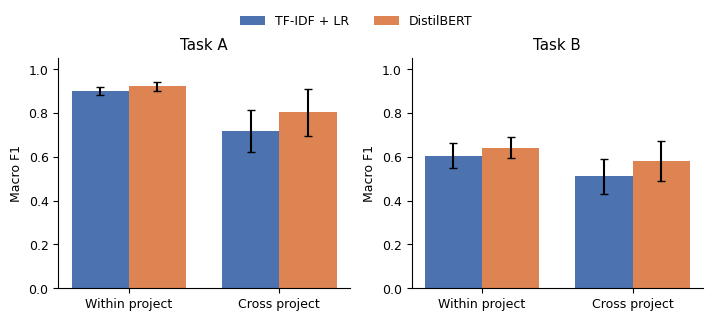

In [18]:
CROSS = {}
for task in ['A', 'B']:
    if not RUN_FULL:
        break
    T = TASKS[task]; n_lab = len(T['le'].classes_); best = RESULTS[task]['best']
    X, y = T['X_all'], T['y_all']; b_f, m_f = [], []
    for i, (tr, va) in enumerate(T['cp_folds']):
        b_f.append(macro_f1_present(y[va], fit_baseline(task, X[tr], y[tr]).predict(X[va])))
        _, pred = cached_transformer(f"{task}|cp|f{i}|{cfg_key(best)}", X[tr], y[tr], X[va], y[va], n_lab, **best)
        m_f.append(macro_f1_present(y[va], pred))
    b_f, m_f = np.array(b_f), np.array(m_f); d_cp = m_f - b_f
    d_within = RESULTS[task]['fold_f1'] - BASELINE[task]['fold_f1']
    n_tr = np.mean([len(tr) for tr, _ in T['cp_folds']]); n_va = np.mean([len(va) for _, va in T['cp_folds']])
    t, p = corrected_resampled_ttest(d_cp, n_tr, n_va)
    p_w = stats.wilcoxon(d_cp, alternative='greater').pvalue
    rng = np.random.default_rng(SEED)
    boot = np.array([rng.choice(d_cp, len(d_cp)).mean() - rng.choice(d_within, len(d_within)).mean() for _ in range(2000)])
    CROSS[task] = dict(baseline_f1=b_f, transformer_f1=m_f, diff=d_cp, t=t, p_corrected_t=p, p_wilcoxon=p_w, wins=int((d_cp > 0).sum()),
                       advantage_within=d_within.mean(), advantage_cross=d_cp.mean(),
                       delta_advantage=boot.mean(), delta_ci=np.percentile(boot, [2.5, 97.5]),
                       drop_baseline=BASELINE[task]['fold_f1'].mean() - b_f.mean(),
                       drop_transformer=RESULTS[task]['fold_f1'].mean() - m_f.mean())
    c = CROSS[task]
    print(f"Task {task} cross project | baseline {b_f.mean():.3f} +/- {b_f.std(ddof=1):.3f} | DistilBERT {m_f.mean():.3f} +/- {m_f.std(ddof=1):.3f} | "
          f"t {t:.2f}, p {p:.4f}, Wilcoxon p {p_w:.4f}, wins {(d_cp > 0).sum()} of {len(d_cp)}\n   advantage within {c['advantage_within']:+.3f}, cross {c['advantage_cross']:+.3f}, "
          f"difference {c['delta_advantage']:+.3f} [{c['delta_ci'][0]:+.3f}, {c['delta_ci'][1]:+.3f}] | "
          f"drop baseline {c['drop_baseline']:.3f}, DistilBERT {c['drop_transformer']:.3f}")

if RUN_FULL:
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
    for ax, task in zip(axes, ['A', 'B']):
        vals = {'TF-IDF + LR': (BASELINE[task]['fold_f1'], CROSS[task]['baseline_f1']),
                'DistilBERT': (RESULTS[task]['fold_f1'], CROSS[task]['transformer_f1'])}
        x = np.arange(2); w = 0.38
        for j, (name, (wi, cp)) in enumerate(vals.items()):
            col = COLORS['baseline'] if j == 0 else COLORS['transformer']
            ax.bar(x + (j - 0.5) * w, [wi.mean(), cp.mean()], w, yerr=[wi.std(ddof=1), cp.std(ddof=1)],
                   color=col, label=name, capsize=3)
        ax.set_xticks(x, ['Within project', 'Cross project']); ax.set_ylabel('Macro F1'); ax.set_title(f'Task {task}')
        ax.set_ylim(0, 1.05); ax.spines[['top', 'right']].set_visible(False)
    fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.07))
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/cross_project.png', dpi=200, bbox_inches='tight'); plt.show()

### 7.5 Learning curve

n_train  baseline  baseline_std  transformer  transformer_std  \
task fraction                                                                  
A    0.25        154.2     0.804         0.021        0.850            0.028   
     0.50        309.2     0.866         0.034        0.896            0.023   
     1.00        619.2     0.899         0.018        0.923            0.022   
B    0.25         83.2     0.377         0.057        0.252            0.036   
     0.50        167.2     0.457         0.036        0.501            0.046   
     1.00        335.2     0.592         0.080        0.642            0.040   

                gain  
task fraction         
A    0.25      0.046  
     0.50      0.030  
     1.00      0.025  
B    0.25     -0.125  
     0.50      0.044  
     1.00      0.050

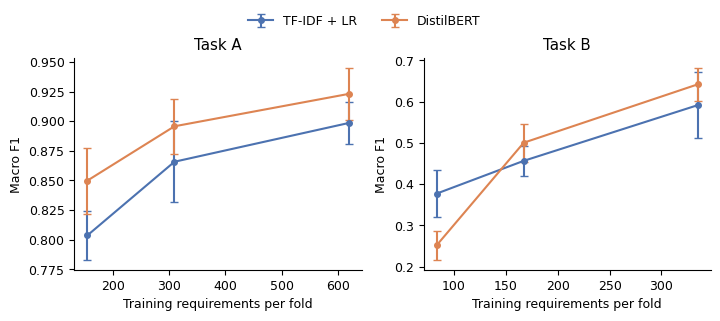

In [19]:
LC = []
for task in ['A', 'B']:
    if not RUN_FULL:
        break
    T = TASKS[task]; n_lab = len(T['le'].classes_); best = RESULTS[task]['best']
    for frac in LC_FRACTIONS + [1.0]:
        for i, (tr, va) in enumerate(T['folds'][:N_SPLITS]):
            if frac < 1:
                sub, _ = train_test_split(tr, train_size=frac, stratify=T['y_dev'][tr], random_state=SEED + i)
                m_f, _ = cached_transformer(f"{task}|lc{frac:g}|f{i}|{cfg_key(best)}", T['X_dev'][sub], T['y_dev'][sub],
                                            T['X_dev'][va], T['y_dev'][va], n_lab, **best)
            else:
                sub = tr; m_f = RESULTS[task]['fold_f1'][i]
            b_f = f1_score(T['y_dev'][va], fit_baseline(task, T['X_dev'][sub], T['y_dev'][sub]).predict(T['X_dev'][va]), average='macro')
            LC.append({'task': task, 'fraction': frac, 'n_train': len(sub), 'fold': i, 'baseline': b_f, 'transformer': m_f})
LC = pd.DataFrame(LC)

if RUN_FULL:
    lc_tab = LC.groupby(['task', 'fraction']).agg(n_train=('n_train', 'mean'), baseline=('baseline', 'mean'),
                                                  baseline_std=('baseline', 'std'), transformer=('transformer', 'mean'),
                                                  transformer_std=('transformer', 'std'))
    lc_tab['gain'] = lc_tab.transformer - lc_tab.baseline
    display(lc_tab.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
    for ax, task in zip(axes, ['A', 'B']):
        d = lc_tab.loc[task]
        for col, name in [('baseline', 'TF-IDF + LR'), ('transformer', 'DistilBERT')]:
            ax.errorbar(d.n_train, d[col], yerr=d[f'{col}_std'], marker='o', ms=4, capsize=3, color=COLORS[col], label=name)
        ax.set_xlabel('Training requirements per fold'); ax.set_ylabel('Macro F1'); ax.set_title(f'Task {task}')
        ax.spines[['top', 'right']].set_visible(False)
    fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.07))
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/learning_curve.png', dpi=200, bbox_inches='tight'); plt.show()

### 7.6 Summary

In [20]:
rows = []
for task in ['A', 'B']:
    T = TASKS[task]
    for name, fold_f1, pred in [('TF-IDF + LR', BASELINE[task]['fold_f1'], BASELINE[task]['y_pred'])] + \
            ([('DistilBERT', RESULTS[task]['fold_f1'], RESULTS[task]['test_pred'])] if task in RESULTS else []):
        p, r, f, _ = precision_recall_fscore_support(T['y_test'], pred, average='macro', zero_division=0)
        rows.append({'task': task, 'model': name, 'cv_macro_f1': fold_f1.mean(), 'cv_std': fold_f1.std(ddof=1),
                     'test_macro_precision': p, 'test_macro_recall': r, 'test_macro_f1': f,
                     'cross_project_f1': (CROSS[task]['baseline_f1' if name == 'TF-IDF + LR' else 'transformer_f1'].mean()
                                          if task in CROSS else np.nan)})
main_tab = pd.DataFrame(rows)
display(main_tab.round(3))

def to_py(o):
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items() if not callable(v)}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, pd.DataFrame):
        return o.reset_index().to_dict(orient='records')
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

if RUN_FULL:
    summary = {
        'run_mode': RUN_MODE, 'device': str(DEVICE), 'torch': torch.__version__,
        'main': main_tab, 'baseline_best': {t: BASELINE[t]['best'] for t in BASELINE},
        'transformer': {t: {k: v for k, v in RESULTS[t].items() if k not in ('fold_pred', 'cv_run', 'test_pred')} for t in RESULTS},
        'baseline_fold_f1': {t: BASELINE[t]['fold_f1'] for t in BASELINE},
        'per_class_B': gain_tab, 'h2_spearman': {'oof_rho': rho_oof, 'oof_p': p_rho_oof, 'test_rho': rho_test, 'test_p': p_rho_test},
        'ablation_B': ABLATION, 'cross_project': CROSS, 'learning_curve': lc_tab,
        'run_seconds_total': sum(v['sec'] for k, v in RUN_CACHE.items() if k.startswith(RUN_MODE)),
        'n_runs': sum(k.startswith(RUN_MODE) for k in RUN_CACHE),
    }
    with open(f'{RESULTS_DIR}/summary.json', 'w') as fh:
        json.dump(to_py(summary), fh, indent=1, default=str)
    print(f"Saved {RESULTS_DIR}/summary.json | {summary['n_runs']} fine-tuning runs, "
          f"{summary['run_seconds_total'] / 3600:.2f} GPU hours in total")

,task,model,cv_macro_f1,cv_std,test_macro_precision,test_macro_recall,test_macro_f1,cross_project_f1
0,A,TF-IDF + LR,0.900,0.018,0.880,0.872,0.874,0.720
1,A,DistilBERT,0.922,0.022,0.881,0.880,0.881,0.804
2,B,TF-IDF + LR,0.606,0.059,0.681,0.647,0.651,0.511
3,B,DistilBERT,0.642,0.049,0.647,0.676,0.644,0.583


Saved results/summary.json | 178 fine-tuning runs, 1.52 GPU hours in total


### 7.7 Findings

Within projects, DistilBERT raises the cross validated macro F1 from 0.900 to 0.922 on Task A and from 0.606 to 0.642 on Task B. The corrected resampled t-test rejects on Task A (p = 0.026) but not on Task B (p = 0.108), and the held out test scores are nearly tied, so H1 is not supported and H3, which predicted no reliable Task A difference, is contradicted. The per class gains show no relation to class frequency (Spearman rho = 0.02), so H2 is not supported.

Across projects both models degrade, but the baseline degrades more, by 0.180 against 0.118 on Task A and 0.096 against 0.059 on Task B. The transformer's advantage grows to 0.084 on Task A and 0.072 on Task B, where it becomes significant (p = 0.030). The increase in advantage has a bootstrap interval of [0.015, 0.104] on Task A and [-0.001, 0.076] on Task B, so H4 is supported on Task A and narrowly misses on Task B.

Class weighting is essential for the baseline, whose Task B macro F1 falls from 0.606 to 0.309 without it, and much less important for the transformer. The learning curve shows that the transformer overtakes the baseline on Task B only once each training fold holds about 15 requirements per class. The paper interprets these results in its Discussion and Conclusion.

## 8. Robustness checks

Two further experiments probe the findings of Section 7. They reuse the configurations selected in Section 7.1 and the same run cache, and together add 124 fine-tuning runs, about one hour on a single GPU.

1. Project vocabulary masking. The Discussion attributes the larger cross project drop of the baseline to vocabulary shift, meaning terms that are specific to one project and act as cues only when that project appears on both sides of a split. To test this directly, every term that occurs in at least two requirements but in only one project is replaced by `[MASK]`, and both models are rescored on the 15 within project folds. If the explanation holds, masking should cost the baseline more than the transformer.
2. Seed variation. Every run in Section 7 used seed 42. The selected DistilBERT configurations are retrained with seeds 1 and 2 on all 15 within project folds and on the test split for both tasks, and on the 15 cross project folds for Task B, where the H4 decision was closest. Fold scores are averaged over the three seeds and the paired tests are repeated.

### 8.1 Project vocabulary masking

In [21]:
import re
TOKEN_RE = re.compile(r'[a-z][a-z0-9]+')
WORD_RE = re.compile(r'[A-Za-z][A-Za-z0-9]+')

def project_exclusive_terms(texts, groups, min_docs=2):
    # Terms that occur in at least min_docs requirements, all of them from a single project.
    occ = {}
    for t, g in zip(texts, groups):
        for w in set(TOKEN_RE.findall(t.lower())):
            occ.setdefault(w, []).append(g)
    return {w: gs[0] for w, gs in occ.items() if len(gs) >= min_docs and len(set(gs)) == 1}

EXCLUSIVE = project_exclusive_terms(df['RequirementText'].values, df['ProjectID'].values)

def mask_text(t):
    return WORD_RE.sub(lambda m: '[MASK]' if m.group(0).lower() in EXCLUSIVE else m.group(0), t)

all_tokens = [w for t in df['RequirementText'] for w in TOKEN_RE.findall(t.lower())]
masked_share = np.mean([w in EXCLUSIVE for w in all_tokens])
req_share = np.mean([any(w in EXCLUSIVE for w in TOKEN_RE.findall(t.lower())) for t in df['RequirementText']])
doc_freq = pd.Series({w: sum(w in set(TOKEN_RE.findall(t.lower())) for t in df['RequirementText']) for w in EXCLUSIVE})
MASK_STATS = {'n_terms': len(EXCLUSIVE), 'token_share': float(masked_share), 'requirement_share': float(req_share),
              'top_terms': doc_freq.sort_values(ascending=False).head(15).to_dict()}
print(f"{len(EXCLUSIVE)} project exclusive terms | {masked_share:.1%} of token occurrences | "
      f"{req_share:.1%} of requirements contain at least one")
print('Most frequent:', ', '.join(f"{w} ({n}, project {EXCLUSIVE[w]})" for w, n in MASK_STATS['top_terms'].items()))
print('Example:', mask_text(TASKS['B']['X_dev'][0]))

275 project exclusive terms | 8.7% of token occurrences | 56.5% of requirements contain at least one
Most frequent: disputes (45, project 4), nursing (34, project 3), clinical (23, project 3), recycled (21, project 5), dispute (20, project 4), classes (19, project 3), movies (17, project 8), leads (15, project 9), players (15, project 10), movie (14, project 8), game (14, project 10), students (14, project 3), streaming (14, project 8), repair (14, project 5), class (13, project 3)
Example: The [MASK] server will have anti-virus software to prevent infection of malicious viruses.


In [22]:
MASKED = {}
for task in ['A', 'B']:
    if not RUN_FULL:
        break
    T = TASKS[task]; n_lab = len(T['le'].classes_); best = RESULTS[task]['best']
    Xm = np.array([mask_text(t) for t in T['X_dev']]); y = T['y_dev']
    b_f = np.array([f1_score(y[va], fit_baseline(task, Xm[tr], y[tr]).predict(Xm[va]), average='macro') for tr, va in T['folds']])
    m_f = np.array([cached_transformer(f"{task}|mask|f{i}|{cfg_key(best)}", Xm[tr], y[tr], Xm[va], y[va], n_lab, **best)[0]
                    for i, (tr, va) in enumerate(T['folds'])])
    drop_b = BASELINE[task]['fold_f1'] - b_f; drop_m = RESULTS[task]['fold_f1'] - m_f
    t, p = corrected_resampled_ttest(drop_b - drop_m, len(T['folds'][0][0]), len(T['folds'][0][1]))
    MASKED[task] = dict(baseline_f1=b_f, transformer_f1=m_f, drop_baseline=drop_b.mean(), drop_transformer=drop_m.mean(),
                        diff=(drop_b - drop_m).mean(), t=t, p_corrected_t=p)
    print(f"Task {task} masked | baseline {b_f.mean():.3f} (drop {drop_b.mean():+.3f}) | DistilBERT {m_f.mean():.3f} "
          f"(drop {drop_m.mean():+.3f}) | baseline minus transformer drop {(drop_b - drop_m).mean():+.3f}, t {t:.2f}, p {p:.4f}")

   ran pretrained|A|mask|f0|lr=5e-05|ep=6|len=64|w=1 | F1 0.941 | 24.8s | 179 runs cached
   ran pretrained|A|mask|f1|lr=5e-05|ep=6|len=64|w=1 | F1 0.890 | 50.0s | 180 runs cached
   ran pretrained|A|mask|f2|lr=5e-05|ep=6|len=64|w=1 | F1 0.961 | 53.3s | 181 runs cached
   ran pretrained|A|mask|f3|lr=5e-05|ep=6|len=64|w=1 | F1 0.916 | 53.0s | 182 runs cached
   ran pretrained|A|mask|f4|lr=5e-05|ep=6|len=64|w=1 | F1 0.908 | 35.3s | 183 runs cached
   ran pretrained|A|mask|f5|lr=5e-05|ep=6|len=64|w=1 | F1 0.909 | 28.0s | 184 runs cached
   ran pretrained|A|mask|f6|lr=5e-05|ep=6|len=64|w=1 | F1 0.948 | 49.1s | 185 runs cached
   ran pretrained|A|mask|f7|lr=5e-05|ep=6|len=64|w=1 | F1 0.935 | 54.2s | 186 runs cached
   ran pretrained|A|mask|f8|lr=5e-05|ep=6|len=64|w=1 | F1 0.915 | 55.4s | 187 runs cached
   ran pretrained|A|mask|f9|lr=5e-05|ep=6|len=64|w=1 | F1 0.922 | 28.8s | 188 runs cached
   ran pretrained|A|mask|f10|lr=5e-05|ep=6|len=64|w=1 | F1 0.921 | 27.4s | 189 runs cached
   ran pr

### 8.2 Seed variation

In [23]:
EXTRA_SEEDS = [1, 2]
SEEDS = {}
for task in ['A', 'B']:
    if not RUN_FULL:
        break
    T = TASKS[task]; n_lab = len(T['le'].classes_); best = RESULTS[task]['best']; ck = cfg_key(best)
    folds_by_seed = [RESULTS[task]['fold_f1']]; tests = [RESULTS[task]['test_f1']]
    for sd in EXTRA_SEEDS:
        folds_by_seed.append(np.array([cached_transformer(f"{task}|cv|f{i}|{ck}|s{sd}", T['X_dev'][tr], T['y_dev'][tr],
                                                          T['X_dev'][va], T['y_dev'][va], n_lab, seed=sd, **best)[0]
                                       for i, (tr, va) in enumerate(T['folds'])]))
        tests.append(cached_transformer(f"{task}|test|{ck}|s{sd}", T['X_dev'], T['y_dev'], T['X_test'], T['y_test'],
                                        n_lab, seed=sd, **best)[0])
    F = np.vstack(folds_by_seed); mean_f = F.mean(axis=0)
    d = mean_f - BASELINE[task]['fold_f1']
    t, p = corrected_resampled_ttest(d, len(T['folds'][0][0]), len(T['folds'][0][1]))
    SEEDS[task] = dict(cv_by_seed=F.mean(axis=1), seed_sd_per_fold=F.std(axis=0, ddof=1).mean(), cv_mean=mean_f.mean(),
                       mean_fold_diff=d.mean(), t=t, p_corrected_t=p, wins=int((d > 0).sum()),
                       test_by_seed=np.array(tests), test_mean=np.mean(tests), mean_fold=mean_f)
    print(f"Task {task} | CV macro F1 by seed {np.round(F.mean(axis=1), 3)} | mean {mean_f.mean():.3f} | "
          f"seed sd per fold {SEEDS[task]['seed_sd_per_fold']:.3f} | gain {d.mean():+.4f}, t {t:.2f}, p {p:.4f}, wins {(d > 0).sum()} of 15 | "
          f"test by seed {np.round(tests, 3)}")

if RUN_FULL:
    # Task B cross project, where the H4 interval was closest to zero
    T = TASKS['B']; n_lab = len(T['le'].classes_); best = RESULTS['B']['best']; ck = cfg_key(best)
    X, y = T['X_all'], T['y_all']
    cp_by_seed = [CROSS['B']['transformer_f1']]
    for sd in EXTRA_SEEDS:
        cp_by_seed.append(np.array([macro_f1_present(y[va], cached_transformer(f"B|cp|f{i}|{ck}|s{sd}", X[tr], y[tr], X[va], y[va],
                                                                                n_lab, seed=sd, **best)[1])
                                    for i, (tr, va) in enumerate(T['cp_folds'])]))
    cp_mean = np.vstack(cp_by_seed).mean(axis=0)
    d_cp = cp_mean - CROSS['B']['baseline_f1']; d_within = SEEDS['B']['mean_fold'] - BASELINE['B']['fold_f1']
    n_tr = np.mean([len(tr) for tr, _ in T['cp_folds']]); n_va = np.mean([len(va) for _, va in T['cp_folds']])
    t, p = corrected_resampled_ttest(d_cp, n_tr, n_va)
    rng = np.random.default_rng(SEED)
    boot = np.array([rng.choice(d_cp, len(d_cp)).mean() - rng.choice(d_within, len(d_within)).mean() for _ in range(2000)])
    SEEDS['B_cross'] = dict(cp_by_seed=np.vstack(cp_by_seed).mean(axis=1), cp_mean=cp_mean.mean(), advantage_cross=d_cp.mean(),
                            advantage_within=d_within.mean(), t=t, p_corrected_t=p, wins=int((d_cp > 0).sum()),
                            delta_advantage=boot.mean(), delta_ci=np.percentile(boot, [2.5, 97.5]))
    c = SEEDS['B_cross']
    print(f"Task B cross project, three seed mean | DistilBERT {cp_mean.mean():.3f} (by seed {np.round(c['cp_by_seed'], 3)}) | "
          f"advantage {d_cp.mean():+.3f}, t {t:.2f}, p {p:.4f}, wins {c['wins']} of 15 | within {d_within.mean():+.3f} | "
          f"difference {c['delta_advantage']:+.3f} [{c['delta_ci'][0]:+.3f}, {c['delta_ci'][1]:+.3f}]")

if RUN_FULL:
    with open(f'{RESULTS_DIR}/robustness.json', 'w') as fh:
        json.dump(to_py({'mask_stats': MASK_STATS, 'masked': MASKED, 'seeds': SEEDS}), fh, indent=1, default=str)
    print(f"Saved {RESULTS_DIR}/robustness.json | {sum(k.startswith(RUN_MODE) for k in RUN_CACHE)} runs cached in total")

   ran pretrained|A|cv|f0|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.935 | 31.1s | 209 runs cached
   ran pretrained|A|cv|f1|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.890 | 38.1s | 210 runs cached
   ran pretrained|A|cv|f2|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.928 | 48.2s | 211 runs cached
   ran pretrained|A|cv|f3|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.890 | 45.9s | 212 runs cached
   ran pretrained|A|cv|f4|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.907 | 41.7s | 213 runs cached
   ran pretrained|A|cv|f5|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.882 | 49.8s | 214 runs cached
   ran pretrained|A|cv|f6|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.928 | 54.5s | 215 runs cached
   ran pretrained|A|cv|f7|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.914 | 28.7s | 216 runs cached
   ran pretrained|A|cv|f8|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.922 | 32.0s | 217 runs cached
   ran pretrained|A|cv|f9|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.909 | 34.6s | 218 runs cached
   ran pretrained|A|cv|f10|lr=5e-05|ep=6|len=64|w=1|s1 | F1 0.922 | 39.3s | 219 runs cache

### 8.3 Findings

Seed variation is substantial on Task B, with a per fold standard deviation of 0.030 across seeds, comparable to the gap between the models. Averaged over three seeds the within project gain is 0.015 on Task A (p = 0.059) and 0.038 on Task B (p = 0.109), so neither is significant, and the Task A result of Section 7.1 is borderline once seed variation is averaged out. On the Task B test split the seeds score 0.644, 0.745, and 0.727 against 0.651 for the baseline. Across projects the seed averaged Task B advantage is 0.085 (p = 0.007), DistilBERT is higher on all 15 grouped folds, and the increase over the within project advantage has an interval of [0.011, 0.084]. With seed variation averaged out, H4 is supported on Task B as well as Task A.

Masking the 275 project exclusive terms changes the baseline by at most 0.013 and DistilBERT by at most 0.017, with no reliable difference between them. The baseline's larger drop on unseen projects is therefore not explained by project names or domain nouns, and more likely reflects differences in how projects phrase and label their requirements.